# 01 — Análisis exploratorio del dataset OhioT1DM

**Objetivo**: caracterizar los 12 pacientes para la sección 3.1 de la memoria y tomar dos
decisiones que condicionan todo el pipeline posterior:

1. **Qué canales puede usar el modelo**, dado que las dos cohortes llevaron pulseras distintas.
2. **Cómo hay que evaluar la hipoglucemia**, dado lo desigual que es su prevalencia.


> Recordatorio de anonimización: las fechas están desplazadas un offset aleatorio por paciente.
> **La hora del día y el día de la semana se conservaron** (son features legítimas); los meses
> se desplazaron, así que **no se puede estudiar estacionalidad**.

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tfm.data import PATIENTS, PATIENTS_2018, PATIENTS_2020, cohort_of
from tfm.data.loaders import availability_matrix, load_cgm, load_summary
from tfm.data import quality as q
from tfm.viz import COHORT_COLORS, FIG_WIDTH_FULL, ROLE, add_glycemic_bands, save_figure, set_style
from tfm.viz.plots import plot_day

set_style()
pd.set_option("display.width", 140)

## 1. Volumen de datos y split oficial

In [2]:
summary = load_summary()
pivot = summary.pivot_table(index=["cohort", "patient"], columns="split",
                            values=["n_cgm", "days"]).round(1)
pivot = pivot[[("n_cgm", "train"), ("n_cgm", "test"), ("days", "train"), ("days", "test")]]
pivot

n_cgm          days      
split             train    test train  test
cohort patient                             
2018   559      10796.0  2514.0  41.9  10.0
       563      12124.0  2570.0  45.5   9.3
       570      10982.0  2745.0  40.3  10.0
       575      11866.0  2590.0  45.5   9.4
       588      12640.0  2791.0  45.5  10.0
       591      10847.0  2760.0  44.3   9.9
2020   540      11947.0  2896.0  45.5  10.6
       544      10623.0  2716.0  44.0  10.9
       552       9080.0  2364.0  38.5  13.7
       567      10858.0  2389.0  47.0  10.0
       584      12150.0  2665.0  46.0  10.4
       596      10877.0  2743.0  47.3  10.4

In [3]:
tr = summary[summary.split == "train"]
print(f"Muestras CGM de entrenamiento: {tr.n_cgm.sum():,}")
print(f"Días de entrenamiento:         {tr.days.sum():.0f}")
print(f"Pacientes:                     {len(PATIENTS)}")

Muestras CGM de entrenamiento: 134,790
Días de entrenamiento:         531
Pacientes:                     12


El volumen total es cómodo para modelos pequeños pero **escaso para
pre-entrenamiento auto-supervisado**, que este trabajo deja como línea futura (capítulo 6 de la
memoria). Si se retoma, el corpus puede ampliarse con los tramos que el pipeline supervisado descarta.

## 2. Disponibilidad de canales: el problema de las dos cohortes

La cohorte 2018 llevó Basis Peak y la de 2020 Empatica Embrace. Antes de diseñar features hay
que ver **qué canal existe de verdad en cada paciente**, no qué canal describe el paper.

In [4]:
av = availability_matrix("train")
av.style.background_gradient(cmap="clinica_secuencial", axis=None).format("{:,.0f}")

patient,559,563,570,575,588,591,540,544,552,567,584,596
channel,,,,,,,,,,,,
acceleration,0,0,0,0,0,0,"28,353","53,219","25,604","39,037","47,024","34,790"
basal,163,87,118,126,74,113,24,103,45,135,27,23
basis_air_temperature,"11,842","11,822","12,232","12,384","12,948","12,086",0,0,0,0,0,0
basis_gsr,"11,769","11,820","12,228","12,340","12,930","12,079","28,353","53,219","25,602","39,037","47,024","34,790"
basis_heart_rate,"11,979","11,966","12,328","12,446","12,980","12,276",0,0,0,0,0,0
basis_skin_temperature,"11,842","11,822","12,232","12,384","12,948","12,086","28,353","53,219","25,598","39,037","47,024","34,790"
basis_sleep,"1,087",876,"1,036",906,"1,082",964,9,52,19,36,38,45
basis_steps,"12,288","11,971","12,335","12,194","13,297","12,054",0,0,0,0,0,0
bolus,152,347,326,187,182,261,309,134,336,313,268,208


In [5]:
present = av > 0
universal = present.index[present.all(axis=1)].tolist()
partial = {c: sorted(present.columns[present.loc[c]]) for c in present.index if not present.loc[c].all()}

print("Disponibles en los 12 pacientes:")
for c in universal:
    print(f"  - {c}")
print("\nCobertura parcial:")
for c, pats in partial.items():
    cohorts = sorted({cohort_of(p) for p in pats})
    print(f"  - {c:26s} {len(pats):2d}/12 pacientes  (cohorte/s: {', '.join(cohorts) or '—'})")

Disponibles en los 12 pacientes:
  - basal
  - basis_gsr
  - basis_skin_temperature
  - basis_sleep
  - bolus
  - finger_stick
  - glucose_level
  - meal
  - temp_basal

Cobertura parcial:
  - acceleration                6/12 pacientes  (cohorte/s: 2020)
  - basis_air_temperature       6/12 pacientes  (cohorte/s: 2018)
  - basis_heart_rate            6/12 pacientes  (cohorte/s: 2018)
  - basis_steps                 6/12 pacientes  (cohorte/s: 2018)
  - exercise                   10/12 pacientes  (cohorte/s: 2018, 2020)
  - hypo_event                  9/12 pacientes  (cohorte/s: 2018, 2020)
  - illness                     8/12 pacientes  (cohorte/s: 2018, 2020)
  - sleep                      11/12 pacientes  (cohorte/s: 2018, 2020)
  - stressors                   4/12 pacientes  (cohorte/s: 2018, 2020)
  - work                        8/12 pacientes  (cohorte/s: 2018, 2020)


### Conjunto de features

- **Núcleo del modelo**: CGM, insulina basal y temporal, bolos, comidas.
- **Pulsera**: solo GSR y temperatura de piel existen en ambas cohortes, y **con frecuencias
  distintas**.
- **Frecuencia cardiaca, pasos y temperatura del aire quedan fuera del modelo principal**: solo
  existen para 6 pacientes. Se reservan para una ablación restringida a la cohorte 2018.
- Los canales autorreportados con cobertura baja no pueden ser entradas fiables.

## 3. Control glucémico por paciente

Time-in-range calculado con los umbrales clínicos estándar. En el test se aplica la regla
oficial del BGLP Challenge (la cohorte 2020 descarta su primera hora).

In [6]:
rows = []
for p in PATIENTS:
    for split in ("train", "test"):
        cgm = load_cgm(p, split)
        rows.append({"patient": p, "cohort": cohort_of(p), "split": split, **q.time_in_range(cgm)})
tir = pd.DataFrame(rows)
tir.round(2).pivot_table(index=["cohort", "patient"], columns="split",
                         values=["pct_hypo", "pct_in_range", "mean", "cv"]).round(1)

cv         mean        pct_hypo       pct_in_range      
split           test train   test  train     test train         test train
cohort patient                                                            
2018   559      39.5  42.3  169.5  166.7      2.9   3.8         58.8  56.2
       563      27.6  34.0  167.4  146.1      0.5   2.3         60.6  74.2
       570      30.9  33.2  214.8  187.5      0.3   1.8         29.8  43.2
       575      40.2  42.5  150.5  141.8      5.2   8.1         63.7  69.2
       588      27.8  30.6  175.1  165.0      0.1   1.0         54.4  63.7
       591      35.5  37.2  144.8  156.0      4.9   3.7         67.6  64.2
2020   540      42.3  40.1  158.6  137.1      4.7   6.4         62.2  73.2
       544      34.7  36.2  156.6  165.2      1.0   1.4         68.3  63.8
       552      37.5  37.2  140.6  146.7      2.7   3.4         78.3  72.3
       567      37.4  39.6  145.7  153.8      8.0   6.4         68.2  64.0
       584      35.7  34.0  169.9  192.5      1.0   0.9         62.2  47.4
       596      34.2  33.5  147.8  147.2      2.4   1.9         74.6  74.2

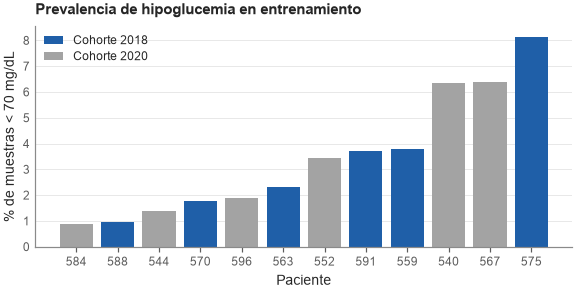

In [7]:
fig, ax = plt.subplots(figsize=(FIG_WIDTH_FULL, 2.6))
sub = tir[tir.split == "train"].sort_values("pct_hypo")
ax.bar(sub.patient, sub.pct_hypo, color=[COHORT_COLORS[c] for c in sub.cohort])
ax.set_ylabel("% de muestras < 70 mg/dL")
ax.set_xlabel("Paciente")
ax.set_title("Prevalencia de hipoglucemia en entrenamiento")
ax.legend([plt.Rectangle((0, 0), 1, 1, color=COHORT_COLORS[c]) for c in ("2018", "2020")],
          ["Cohorte 2018", "Cohorte 2020"], loc="upper left")
save_figure(fig, "01_prevalencia_hipoglucemia")
plt.show()

In [8]:
from tfm.data.loaders import load_cgm
from tfm.data.parser import PATIENTS

# prevalencia a nivel de muestra (glucosa < 70 mg/dL), agregada sobre los 12 pacientes
for split in ("train", "test"):
    series = [load_cgm(p, split)["value"].to_numpy() for p in PATIENTS]
    v = np.concatenate(series)
    por_paciente = [100 * np.mean(s < 70) for s in series]
    print(f"{split}: {100 * np.mean(v < 70):.2f} % de {len(v):,} muestras bajo 70 mg/dL "
          f"(por paciente, {min(por_paciente):.2f}–{max(por_paciente):.2f} %)")

train: 3.41 % de 134,790 muestras bajo 70 mg/dL (por paciente, 0.88–8.13 %)
test: 2.76 % de 31,671 muestras bajo 70 mg/dL (por paciente, 0.11–7.95 %)


La prevalencia varía **casi en un factor 10 entre pacientes** (0,9 % a 8,1 %). Esto es el
argumento empírico de la personalización: un modelo global ve una mezcla de regímenes
glucémicos muy distintos.

## 4. Hipoglucemia como **eventos**, no como muestras

Un episodio abarca muchas muestras consecutivas, así que el porcentaje de muestras exagera
cuánta evidencia independiente hay. Contamos episodios de al menos 15 minutos bajo 70 mg/dL,
siguiendo el consenso internacional de reporte de CGM.

In [9]:
rows = []
for p in PATIENTS:
    for split in ("train", "test"):
        cgm = load_cgm(p, split)
        ev = q.glycemic_events(cgm, threshold=q.HYPO)
        sev = q.glycemic_events(cgm, threshold=q.SEVERE_HYPO)
        rows.append({
            "patient": p, "cohort": cohort_of(p), "split": split,
            "n_eventos": len(ev),
            "n_eventos_severos": len(sev),
            "muestras_hipo": int((cgm["value"] < q.HYPO).sum()),
            "duracion_mediana_min": ev["minutes"].median() if len(ev) else np.nan,
            "nadir_medio": ev["nadir"].mean() if len(ev) else np.nan,
        })
events = pd.DataFrame(rows)
events[events.split == "test"].set_index(["cohort", "patient"]).drop(columns="split").round(1)

n_eventos  n_eventos_severos  muestras_hipo  duracion_mediana_min  nadir_medio
cohort patient                                                                                
2018   559              3                  2             72                 105.0         50.3
       563              2                  0             14                  32.5         64.5
       570              2                  0              9                  22.5         63.0
       575              9                  6            134                  65.0         51.9
       588              1                  0              3                  15.0         66.0
       591             13                  1            134                  45.0         55.6
2020   540             12                  2            135                  30.0         56.8
       544              2                  0             28                  50.0         63.0
       552              7                  1             64                  45.0         57.9
       567              7                  2            189                 105.0         53.1
       584              3                  1             26                  20.0         55.3
       596              8                  1             65                  35.0         57.1

In [10]:
test_ev = events[events.split == "test"]
print(f"Eventos de hipoglucemia en el test, total de los 12 pacientes: {test_ev.n_eventos.sum()}")
print()
escasos = test_ev[test_ev.n_eventos < 5]
print("Pacientes con menos de 5 eventos en su test:")
print(escasos[["patient", "n_eventos", "muestras_hipo"]].to_string(index=False))

Eventos de hipoglucemia en el test, total de los 12 pacientes: 69

Pacientes con menos de 5 eventos en su test:
patient  n_eventos  muestras_hipo
    559          3             72
    563          2             14
    570          2              9
    588          1              3
    544          2             28
    584          3             26


### Cómo se reporta el recall de hipoglucemia

Hay pacientes cuyo test contiene unos pocos episodios. Un recall individual salta de
0 a 1 con un solo acierto: no es una medida, es ruido.

**Protocolo de evaluación adoptado**:

1. La métrica principal es el **recall agregado sobre los eventos de los 12 pacientes**.
2. Toda tabla por paciente muestra el **número absoluto de eventos** junto al porcentaje.
3. En los pacientes con muy pocos eventos no se interpreta el recall individual; se usan para
   el agregado y para el análisis cualitativo.

## 5. Calidad de la señal: huecos y segmentos

Las ventanas de entrenamiento no pueden cruzar un hueco del sensor. Medimos cuánto se pierde.

In [11]:
rows = []
for p in PATIENTS:
    cgm = load_cgm(p, "train")
    gaps = q.gap_table(cgm)
    segs = q.segment_table(cgm)
    largos = gaps[gaps.minutes > q.MAX_INTERP_GAP_MIN]
    rows.append({
        "patient": p, "cohort": cohort_of(p),
        "n_huecos": len(gaps),
        "n_huecos_largos": len(largos),
        "horas_perdidas": gaps.minutes.sum() / 60,
        "hueco_max_h": gaps.minutes.max() / 60 if len(gaps) else 0,
        "n_segmentos": len(segs),
        "segmento_mediano_h": segs.minutes.median() / 60,
        "pct_imputado": segs.pct_imputed.mean(),
    })
gapinfo = pd.DataFrame(rows).set_index(["cohort", "patient"])
gapinfo.round(2)

n_huecos  n_huecos_largos  horas_perdidas  hueco_max_h  n_segmentos  segmento_mediano_h  pct_imputado
cohort patient                                                                                                       
2018   559            42               34          107.08        12.92           35               21.50          0.27
       563            21               11           81.08        24.00           12               79.38          0.22
       570            20               17           52.42        12.08           18               32.33          0.05
       575            72               36          103.08        11.33           37               15.08          0.71
       588            10               10           38.75        12.58           11              129.67          0.00
       591            26               18          159.08        80.50           19               43.25          0.24
2020   540            29               20           96.83        19.58           21               29.67          0.22
       544            22               20          170.75        61.50           21               21.25          0.04
       552            43               24          168.17        43.42           25               23.83          0.57
       567            57               48          223.17        26.33           49               20.25          0.17
       584            59               31           91.50        14.67           32               25.75          0.54
       596            25               18          229.42        49.33           19               22.75          1.00

Los huecos cortos (≤ 30 min) se interpolan y se marcan con `is_imputed` y los largos **parten la
serie en segmentos** y ninguna ventana los cruza. Esa es la razón de que el número de ventanas
utilizables sea menor que el de muestras.

## 6. Perfil circadiano

Legítimo porque la anonimización conservó la hora del día. Es la justificación empírica de
codificar la hora como `sin`/`cos`.

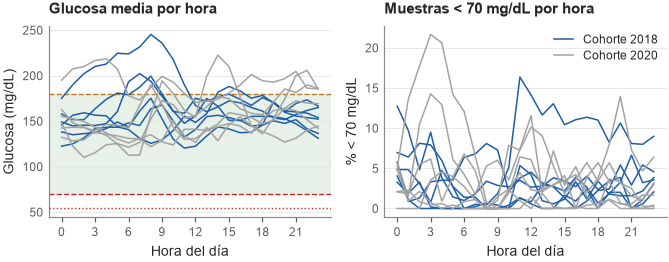

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(FIG_WIDTH_FULL, 2.6))

for p in PATIENTS:
    prof = q.circadian_profile(load_cgm(p, "train"))
    cohort = "2018" if p in PATIENTS_2018 else "2020"
    for ax, col in ((axes[0], "mean"), (axes[1], "pct_hypo")):
        ax.plot(prof.hour, prof[col], lw=1.0, color=COHORT_COLORS[cohort],
                label=f"Cohorte {cohort}")
handles, labels = axes[1].get_legend_handles_labels()
uniq = dict(zip(labels, handles))
axes[1].legend(uniq.values(), uniq.keys(), loc="upper right")

add_glycemic_bands(axes[0])
axes[0].set_title("Glucosa media por hora")
axes[0].set_xlabel("Hora del día")
axes[1].set_title("Muestras < 70 mg/dL por hora")
axes[1].set_xlabel("Hora del día")
axes[1].set_ylabel("% < 70 mg/dL")
for ax in axes:
    ax.set_xticks(range(0, 24, 3))
fig.tight_layout()
save_figure(fig, "01_perfil_circadiano")
plt.show()

Episodios de hipoglucemia en entrenamiento: 414
De ellos, iniciados entre 00:00 y 06:00:     85 (20.5 %)
Duración mediana nocturna: 55 min  |  diurna: 45 min


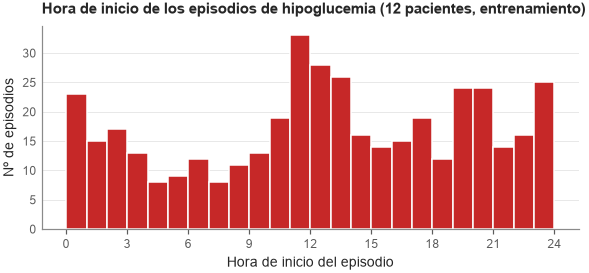

In [13]:
# ¿Cuándo empiezan los episodios? La hipoglucemia nocturna es la clínicamente más peligrosa,
# porque el paciente duerme y no la percibe.
horas = pd.concat([q.glycemic_events(load_cgm(p, "train")).assign(patient=p) for p in PATIENTS])
nocturnos = horas[(horas.hour >= 0) & (horas.hour < 6)]
print(f"Episodios de hipoglucemia en entrenamiento: {len(horas)}")
print(f"De ellos, iniciados entre 00:00 y 06:00:     {len(nocturnos)} ({100*len(nocturnos)/len(horas):.1f} %)")
print(f"Duración mediana nocturna: {nocturnos.minutes.median():.0f} min  |  diurna: {horas[~horas.index.isin(nocturnos.index)].minutes.median():.0f} min")

fig, ax = plt.subplots(figsize=(FIG_WIDTH_FULL, 2.4))
ax.hist(horas.hour, bins=range(25), color=ROLE["hipo"], edgecolor="white", linewidth=1)
ax.set_xlabel("Hora de inicio del episodio")
ax.set_ylabel("Nº de episodios")
ax.set_title("Hora de inicio de los episodios de hipoglucemia (12 pacientes, entrenamiento)")
ax.set_xticks(range(0, 25, 3))
save_figure(fig, "01_hipoglucemia_por_hora")
plt.show()

## 7. Ejemplo cualitativo: un día con hipoglucemia

Sirve para desarrollar intuición y, más adelante, para inspeccionar predicciones malas —el uso
que los propios autores del dataset recomiendan para el OhioT1DM Viewer.

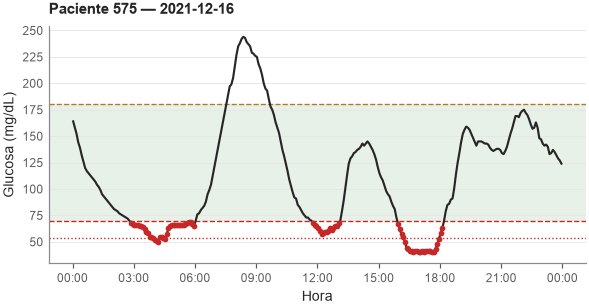

In [14]:
p = "575"  # uno de los pacientes con más hipoglucemia
cgm = load_cgm(p, "train")
ev = q.glycemic_events(cgm)
dia = ev.sort_values("minutes", ascending=False).iloc[0]["start"]

fig, ax = plt.subplots(figsize=(FIG_WIDTH_FULL, 2.8))
plot_day(ax, cgm, dia)
ax.set_title(f"Paciente {p} — {pd.Timestamp(dia).date()}")
save_figure(fig, "01_dia_ejemplo")
plt.show()

## 8. Conclusiones del EDA

- 12 pacientes, ~135k muestras CGM de entrenamiento (531 días) y el split oficial respetado,
  con la exclusión de la primera hora del test en la cohorte 2020.
- Control glucémico muy heterogéneo entre pacientes: la prevalencia de hipoglucemia varía casi
  en un factor 10. **Es el argumento empírico de la personalización.**
- La señal tiene huecos frecuentes; la segmentación reduce las ventanas utilizables.
- El perfil circadiano es marcado y la hipoglucemia se concentra de forma desigual a lo largo
  del día, con un componente nocturno relevante.

**Decisiones tomadas**:

| Decisión | Resultado |
|---|---|
| Features de pulsera | Solo GSR y temperatura de piel (reagregadas a 5 min). HR/pasos → ablación solo 2018 |
| Evaluación de hipoglucemia | Recall agregado **por eventos**; nº absoluto junto a cada porcentaje |
| Huecos | ≤ 30 min interpolados y marcados; mayores parten la serie en segmentos |
| Hora del día | Feature legítima (`sin`/`cos`); estacionalidad prohibida |